# Lab Sheet-IV

Boundary value problems: finite differences and collocation. All differences are 2nd order.

## Q1. FD with derivative BCs

$y''=y'+2y$, $y(0)+y'(0)=0$, $y(1)-y'(1)=2/e$, exact $e^{-x}$  
interior: central differences; boundaries: $y'(x_0)\approx\frac{-3y_0+4y_1-y_2}{2h}$, $y'(x_N)\approx\frac{3y_N-4y_{N-1}+y_{N-2}}{2h}$  \nextra entries removed by row operations, then Thomas algorithm

--- h = 0.1 ---
     x         y num         exact       |error|
  0.00    0.98725592    1.00000000    1.2744e-02
  0.10    0.89296743    0.90483742    1.1870e-02
  0.20    0.80755316    0.81873075    1.1178e-02
  0.30    0.73014902    0.74081822    1.0669e-02
  0.40    0.65996864    0.67032005    1.0351e-02
  0.50    0.59629493    0.60653066    1.0236e-02
  0.60    0.53847231    0.54881164    1.0339e-02
  0.70    0.48589934    0.49658530    1.0686e-02
  0.80    0.43802185    0.44932896    1.1307e-02
  0.90    0.39432612    0.40656966    1.2244e-02
  1.00    0.35433245    0.36787944    1.3547e-02



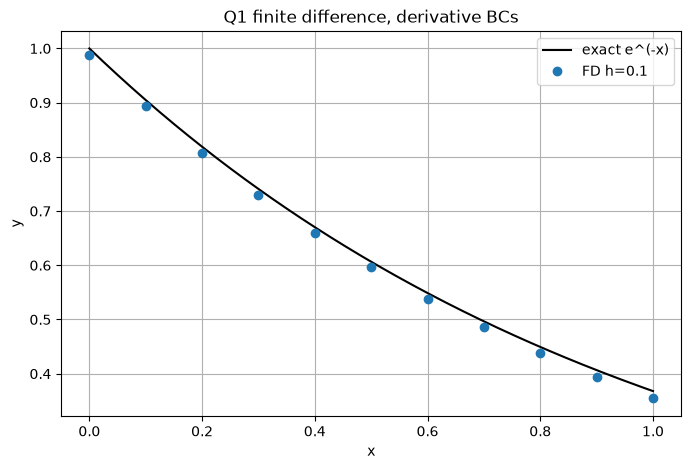

--- h = 0.05 ---
     x         y num         exact       |error|
  0.00    0.99663098    1.00000000    3.3690e-03
  0.10    0.90170122    0.90483742    3.1362e-03
  0.20    0.81577984    0.81873075    2.9509e-03
  0.30    0.73800453    0.74081822    2.8137e-03
  0.40    0.66759385    0.67032005    2.7262e-03
  0.50    0.60383933    0.60653066    2.6913e-03
  0.60    0.54609814    0.54881164    2.7135e-03
  0.70    0.49378653    0.49658530    2.7988e-03
  0.80    0.44637372    0.44932896    2.9552e-03
  0.90    0.40337626    0.40656966    3.1934e-03
  1.00    0.36435289    0.36787944    3.5265e-03

--- h = 0.025 ---
     x         y num         exact       |error|
  0.00    0.99913738    1.00000000    8.6262e-04
  0.10    0.90403453    0.90483742    8.0289e-04
  0.20    0.81797548    0.81873075    7.5528e-04
  0.30    0.74009830    0.74081822    7.1992e-04
  0.40    0.66962281    0.67032005    6.9723e-04
  0.50    0.60584270    0.60653066    6.8796e-04
  0.60    0.54811844    0.5488116

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def exact(x):
    return np.exp(-x)


def thomas(A, B, C, F):
    # tridiagonal system: A[i] y[i-1] + C[i] y[i] + B[i] y[i+1] = F[i]   (notes: Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    y = np.zeros(n)
    y[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        y[i] = alpha[i + 1]*y[i + 1] + beta[i + 1]
    return y


def fd_solve(h):
    # y'' + p y' + q y = f  with p = -1, q = -2, f = 0
    # BCs: a0 y(0) + b0 y'(0) = c0  (1, 1, 0),   a1 y(1) + b1 y'(1) = c1  (1, -1, 2/e)
    N = int(round(1/h))
    x = np.linspace(0, 1, N + 1)
    p, q = -1.0, -2.0
    a0, b0, c0 = 1.0, 1.0, 0.0
    a1, b1, c1 = 1.0, -1.0, 2/np.e

    A = np.zeros(N + 1)      # below diagonal (coefficient of y[i-1])
    C = np.zeros(N + 1)      # diagonal
    B = np.zeros(N + 1)      # above diagonal (coefficient of y[i+1])
    F = np.zeros(N + 1)

    # interior rows: central differences
    for i in range(1, N):
        A[i] = 1/h**2 - p/(2*h)
        C[i] = -(2/h**2 - q)
        B[i] = 1/h**2 + p/(2*h)
        F[i] = 0.0

    # row 0: y'(x0) ~ (-3y0 + 4y1 - y2)/(2h)  ->  C0 y0 + B0 y1 + R0 y2 = c0
    C[0] = a0 - 3*b0/(2*h)
    B[0] = 4*b0/(2*h)
    R0 = -b0/(2*h)
    F[0] = c0

    # row N: y'(xN) ~ (3yN - 4y_{N-1} + y_{N-2})/(2h)  ->  PN y_{N-2} + AN y_{N-1} + CN yN = c1
    PN = b1/(2*h)
    A[N] = -4*b1/(2*h)
    C[N] = a1 + 3*b1/(2*h)
    F[N] = c1

    # make tridiagonal: row 0 - (R0/B1) row 1,  row N - (PN/A_{N-1}) row N-1
    m = R0/B[1]
    C[0] -= m*A[1]
    B[0] -= m*C[1]
    F[0] -= m*F[1]
    m = PN/A[N - 1]
    A[N] -= m*C[N - 1]
    C[N] -= m*B[N - 1]
    F[N] -= m*F[N - 1]

    y = thomas(A, B, C, F)
    return x, y


max_err = {}
for h in [0.1, 0.05, 0.025]:
    x, y = fd_solve(h)
    err = np.abs(y - exact(x))
    max_err[h] = err.max()

    print(f"--- h = {h} ---")
    print(f"{'x':>6}  {'y num':>12}  {'exact':>12}  {'|error|':>12}")
    every = 1 if h == 0.1 else int(round(0.1/h))
    for i in range(0, len(x), every):
        print(f"{x[i]:6.2f}  {y[i]:12.8f}  {exact(x[i]):12.8f}  {err[i]:12.4e}")
    print()

    if h == 0.1:
        xx = np.linspace(0, 1, 200)
        plt.figure(figsize=(8, 5))
        plt.plot(xx, exact(xx), "k-", label="exact e^(-x)")
        plt.plot(x, y, "o", label="FD h=0.1")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title("Q1 finite difference, derivative BCs")
        plt.legend()
        plt.grid()
        plt.show()

hs = [0.1, 0.05, 0.025]
print(f"{'h':>8}  {'max error':>12}  {'ratio':>8}  {'order p':>8}")
for k in range(len(hs)):
    if k == 0:
        print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}")
    else:
        ratio = max_err[hs[k-1]]/max_err[hs[k]]
        print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}  {ratio:8.2f}  {np.log2(ratio):8.2f}")
print("\nratio ~4 when h is halved => 2nd order (one-sided 3-point formulas at the boundaries are also 2nd order)")

## Q2. FD with Dirichlet BCs

$y''=y+x$, $y(0)=y(1)=0$, exact $\frac{\sinh x}{\sinh 1}-x$  
$y_{i-1}-(2+h^2)y_i+y_{i+1}=h^2x_i$, $i=1..N-1$, solved by Thomas algorithm

tridiagonal matrix (h = 0.1):
[[-2.01  1.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 1.   -2.01  1.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    1.   -2.01  1.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    1.   -2.01  1.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    1.   -2.01  1.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    1.   -2.01  1.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    1.   -2.01  1.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    1.   -2.01  1.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    1.   -2.01]]
right-hand side h^2 x_i:
[0.001 0.002 0.003 0.004 0.005 0.006 0.007 0.008 0.009]

--- h = 0.1 ---
     x         y num         exact       |error|
  0.00    0.00000000    0.00000000    0.0000e+00
  0.10   -0.01475531   -0.01476630    1.0985e-05
  0.20   -0.02865818   -0.02867955    2.1370e-05
  0.30   -0.04084762   -0.04087816    3.0540e-05
  0.40   -0.05044554   -0.05048340    3.7855e-05
  0.50   -0.05654792   -0.05659056    4.2636e-05
  0.60   -0.058

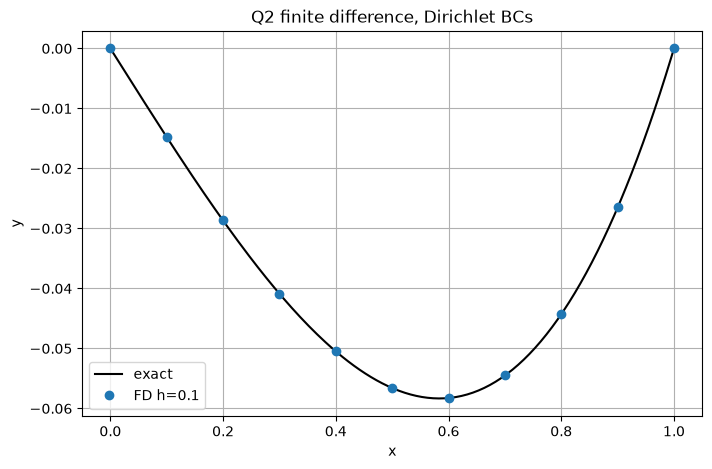

--- h = 0.05 ---
     x         y num         exact       |error|
  0.00    0.00000000    0.00000000    0.0000e+00
  0.10   -0.01476355   -0.01476630    2.7489e-06
  0.20   -0.02867420   -0.02867955    5.3474e-06
  0.30   -0.04087052   -0.04087816    7.6421e-06
  0.40   -0.05047393   -0.05048340    9.4727e-06
  0.50   -0.05657989   -0.05659056    1.0669e-05
  0.60   -0.05824888   -0.05825993    1.1047e-05
  0.70   -0.05449697   -0.05450738    1.0405e-05
  0.80   -0.04428600   -0.04429452    8.5212e-06
  0.90   -0.02651316   -0.02651831    5.1460e-06
  1.00    0.00000000    0.00000000    0.0000e+00

--- h = 0.025 ---
     x         y num         exact       |error|
  0.00    0.00000000    0.00000000    0.0000e+00
  0.10   -0.01476561   -0.01476630    6.8737e-07
  0.20   -0.02867821   -0.02867955    1.3372e-06
  0.30   -0.04087625   -0.04087816    1.9110e-06
  0.40   -0.05048103   -0.05048340    2.3687e-06
  0.50   -0.05658789   -0.05659056    2.6679e-06
  0.60   -0.05825716   -0.0582599

In [2]:
import numpy as np
import matplotlib.pyplot as plt


def exact(x):
    return np.sinh(x)/np.sinh(1) - x


def thomas(A, B, C, F):
    # tridiagonal system: A[i] y[i-1] + C[i] y[i] + B[i] y[i+1] = F[i]   (notes: Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    y = np.zeros(n)
    y[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        y[i] = alpha[i + 1]*y[i + 1] + beta[i + 1]
    return y


def fd_solve(h, show=False):
    # (y[i-1] - 2y[i] + y[i+1])/h^2 = y[i] + x[i]
    # => y[i-1] - (2 + h^2) y[i] + y[i+1] = h^2 x[i],  i = 1..N-1,  y[0] = y[N] = 0
    N = int(round(1/h))
    x = np.linspace(0, 1, N + 1)
    m = N - 1                       # number of unknowns
    A = np.ones(m)                  # below diagonal (A[0] not used)
    C = -(2 + h**2)*np.ones(m)      # diagonal
    B = np.ones(m)                  # above diagonal (B[m-1] not used)
    F = h**2*x[1:N]                 # boundary values are 0, nothing to add

    if show:
        M = np.diag(C) + np.diag(A[1:], -1) + np.diag(B[:-1], 1)   # only for printing
        np.set_printoptions(linewidth=150)
        print("tridiagonal matrix (h = 0.1):")
        print(M)
        print("right-hand side h^2 x_i:")
        print(F)
        print()

    y = np.zeros(N + 1)
    y[1:N] = thomas(A, B, C, F)
    return x, y


max_err = {}
for h in [0.1, 0.05, 0.025]:
    x, y = fd_solve(h, show=(h == 0.1))
    err = np.abs(y - exact(x))
    max_err[h] = err.max()

    print(f"--- h = {h} ---")
    print(f"{'x':>6}  {'y num':>12}  {'exact':>12}  {'|error|':>12}")
    every = 1 if h == 0.1 else int(round(0.1/h))
    for i in range(0, len(x), every):
        print(f"{x[i]:6.2f}  {y[i]:12.8f}  {exact(x[i]):12.8f}  {err[i]:12.4e}")
    print()

    if h == 0.1:
        xx = np.linspace(0, 1, 200)
        plt.figure(figsize=(8, 5))
        plt.plot(xx, exact(xx), "k-", label="exact")
        plt.plot(x, y, "o", label="FD h=0.1")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title("Q2 finite difference, Dirichlet BCs")
        plt.legend()
        plt.grid()
        plt.show()

hs = [0.1, 0.05, 0.025]
print(f"{'h':>8}  {'max error':>12}  {'ratio':>8}  {'order p':>8}")
for k in range(len(hs)):
    if k == 0:
        print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}")
    else:
        ratio = max_err[hs[k-1]]/max_err[hs[k]]
        print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}  {ratio:8.2f}  {np.log2(ratio):8.2f}")
print("\nratio ~4 when h is halved => 2nd order")

## Q3. FD for nonlinear BVP

$y''=y^2$, $y(0)=6$, $y(1)=1.5$, exact $6/(1+x)^2$  
$F_i=y_{i-1}-2y_i+y_{i+1}-h^2y_i^2=0$, Newton with $J_{ii}=-2-2h^2y_i$, $J_{i,i\pm1}=1$ (each step by Thomas)

--- h = 0.1 ---   Newton iterations: 5
     x         y num         exact       |error|
  0.00    6.00000000    6.00000000    0.0000e+00
  0.10    4.96348374    4.95867769    4.8061e-03
  0.20    4.17332918    4.16666667    6.6625e-03
  0.30    3.55734139    3.55029586    7.0455e-03
  0.40    3.06790038    3.06122449    6.6759e-03
  0.50    2.67257949    2.66666667    5.9128e-03
  0.60    2.34868542    2.34375000    4.9354e-03
  0.70    2.07995457    2.07612457    3.8300e-03
  0.80    1.85448584    1.85185185    2.6340e-03
  0.90    1.66340828    1.66204986    1.3584e-03
  1.00    1.50000000    1.50000000    0.0000e+00
max error = 7.0455e-03



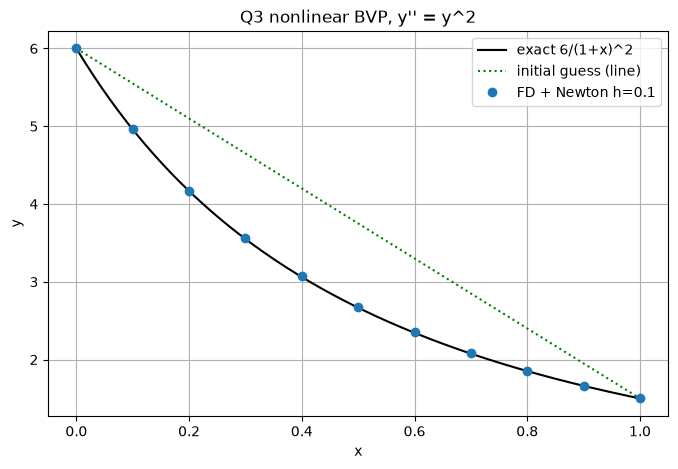

--- h = 0.05 ---   Newton iterations: 5
     x         y num         exact       |error|
  0.00    6.00000000    6.00000000    0.0000e+00
  0.10    4.95989890    4.95867769    1.2212e-03
  0.20    4.16835643    4.16666667    1.6898e-03
  0.30    3.55208019    3.55029586    1.7843e-03
  0.40    3.06291330    3.06122449    1.6888e-03
  0.50    2.66816111    2.66666667    1.4944e-03
  0.60    2.34499651    2.34375000    1.2465e-03
  0.70    2.07709133    2.07612457    9.6676e-04
  0.80    1.85251641    1.85185185    6.6456e-04
  0.90    1.66239246    1.66204986    3.4260e-04
  1.00    1.50000000    1.50000000    0.0000e+00
max error = 1.7843e-03

--- h = 0.025 ---   Newton iterations: 5
     x         y num         exact       |error|
  0.00    6.00000000    6.00000000    0.0000e+00
  0.10    4.95898426    4.95867769    3.0658e-04
  0.20    4.16709067    4.16666667    4.2400e-04
  0.30    3.55074342    3.55029586    4.4756e-04
  0.40    3.06164797    3.06122449    4.2348e-04
  0.50    2.6

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def exact(x):
    return 6/(1 + x)**2


def thomas(A, B, C, F):
    # tridiagonal system: A[i] y[i-1] + C[i] y[i] + B[i] y[i+1] = F[i]   (notes: Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    y = np.zeros(n)
    y[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        y[i] = alpha[i + 1]*y[i + 1] + beta[i + 1]
    return y


def fd_newton(h, tol=1e-10):
    # G_i(y) = y[i-1] - 2y[i] + y[i+1] - h^2 y[i]^2 = 0,  i = 1..N-1
    # Jacobian is tridiagonal: diagonal -2 - 2h^2 y[i], off-diagonals 1
    N = int(round(1/h))
    x = np.linspace(0, 1, N + 1)
    y = 6 + (1.5 - 6)*x             # straight line between boundary values
    m = N - 1
    A = np.ones(m)
    B = np.ones(m)

    for it in range(1, 101):
        G = y[0:N-1] - 2*y[1:N] + y[2:N+1] - h**2*y[1:N]**2
        C = -2 - 2*h**2*y[1:N]
        delta = thomas(A, B, C, -G)     # solve J delta = -G
        y[1:N] += delta
        if np.max(np.abs(delta)) < tol:
            break
    return x, y, it


max_err = {}
for h in [0.1, 0.05, 0.025]:
    x, y, its = fd_newton(h)
    err = np.abs(y - exact(x))
    max_err[h] = err.max()

    print(f"--- h = {h} ---   Newton iterations: {its}")
    print(f"{'x':>6}  {'y num':>12}  {'exact':>12}  {'|error|':>12}")
    every = 1 if h == 0.1 else int(round(0.1/h))
    for i in range(0, len(x), every):
        print(f"{x[i]:6.2f}  {y[i]:12.8f}  {exact(x[i]):12.8f}  {err[i]:12.4e}")
    print(f"max error = {err.max():.4e}\n")

    if h == 0.1:
        xx = np.linspace(0, 1, 200)
        plt.figure(figsize=(8, 5))
        plt.plot(xx, exact(xx), "k-", label="exact 6/(1+x)^2")
        plt.plot(x, 6 - 4.5*x, "g:", label="initial guess (line)")
        plt.plot(x, y, "o", label="FD + Newton h=0.1")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title("Q3 nonlinear BVP, y'' = y^2")
        plt.legend()
        plt.grid()
        plt.show()

hs = [0.1, 0.05, 0.025]
print(f"{'h':>8}  {'max error':>12}  {'ratio':>8}  {'order p':>8}")
for k in range(len(hs)):
    if k == 0:
        print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}")
    else:
        ratio = max_err[hs[k-1]]/max_err[hs[k]]
        print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}  {ratio:8.2f}  {np.log2(ratio):8.2f}")

print("\nratio ~4 when h is halved => 2nd order")
print("Newton converges quadratically: same small number of iterations (5) for every h")

## Q4. Collocation, derivative BCs

$y_N=\sum_{j=0}^N c_jx^j$, BCs exact, ODE at $x_k=k/N$, $k=1..N-1$

  N     max error
  3    3.5902e-02
  4    3.1262e-03
  5    3.3267e-04
  6    1.4583e-05
  7    1.1618e-06

coefficients for N = 7:
  c0 =  0.99999884
  c1 = -0.99999884
  c2 =  0.49999645
  c3 = -0.16665023
  c4 =  0.04161335
  c5 = -0.00823017
  c6 =  0.00126971
  c7 = -0.00012066


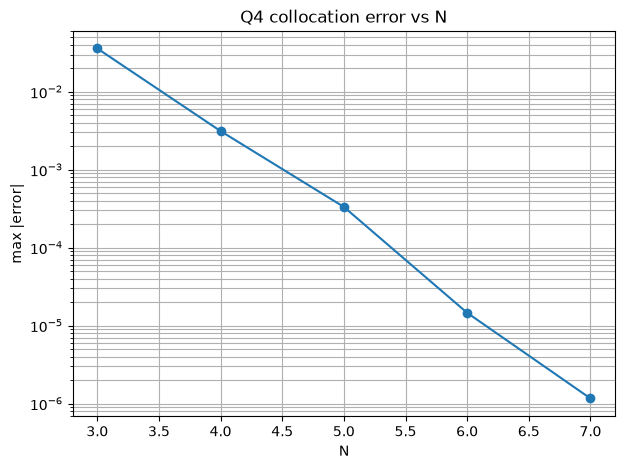

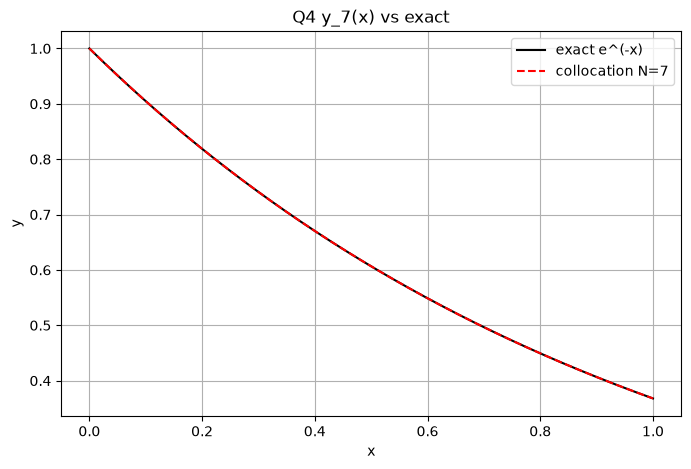

error falls by a roughly constant factor per extra term (straight line on semilog)
=> exponential (spectral) convergence, much faster than the h^2 of finite differences
check: c_j are close to the Taylor coefficients of e^(-x): 1, -1, 1/2, -1/6, 1/24, -1/120, ...


In [4]:
import numpy as np
import matplotlib.pyplot as plt


def exact(x):
    return np.exp(-x)


def collocation(N):
    # y_N = sum c_j x^j,  j = 0..N
    # row 0:    y(0) + y'(0) = c0 + c1 = 0
    # row N:    y(1) - y'(1) = sum c_j (1 - j) = 2/e
    # rows 1..N-1: y'' - y' - 2y = 0 at x_k = k/N
    A = np.zeros((N + 1, N + 1))
    r = np.zeros(N + 1)

    A[0, 0] = 1
    A[0, 1] = 1

    for k in range(1, N):
        xk = k/N
        for j in range(N + 1):
            d2 = j*(j - 1)*xk**(j - 2) if j >= 2 else 0
            d1 = j*xk**(j - 1) if j >= 1 else 0
            A[k, j] = d2 - d1 - 2*xk**j

    for j in range(N + 1):
        A[N, j] = 1 - j
    r[N] = 2/np.e

    return np.linalg.solve(A, r)


def evaluate(c, x):
    y = np.zeros_like(x)
    for j in range(len(c)):
        y += c[j]*x**j
    return y


xx = np.linspace(0, 1, 1001)
Ns = [3, 4, 5, 6, 7]
errs = []
print(f"{'N':>3}  {'max error':>12}")
for N in Ns:
    c = collocation(N)
    e = np.abs(evaluate(c, xx) - exact(xx)).max()
    errs.append(e)
    print(f"{N:3d}  {e:12.4e}")

c7 = collocation(7)
print("\ncoefficients for N = 7:")
for j in range(8):
    print(f"  c{j} = {c7[j]: .8f}")

plt.figure(figsize=(7, 5))
plt.semilogy(Ns, errs, "o-")
plt.xlabel("N")
plt.ylabel("max |error|")
plt.title("Q4 collocation error vs N")
plt.grid(True, which="both")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(xx, exact(xx), "k-", label="exact e^(-x)")
plt.plot(xx, evaluate(c7, xx), "r--", label="collocation N=7")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q4 y_7(x) vs exact")
plt.legend()
plt.grid()
plt.show()

print("error falls by a roughly constant factor per extra term (straight line on semilog)")
print("=> exponential (spectral) convergence, much faster than the h^2 of finite differences")
print("check: c_j are close to the Taylor coefficients of e^(-x): 1, -1, 1/2, -1/6, 1/24, -1/120, ...")

## Q5. Collocation, Dirichlet BCs

$y_N=\sum_{i=1}^N c_ix^i(1-x)$, ODE at $x_k=k/(N+1)$, $k=1..N$

  N     max error
  2    5.8105e-04
  3    6.3081e-05
  4    2.4792e-06
  5    2.1458e-07
  6    5.8747e-09


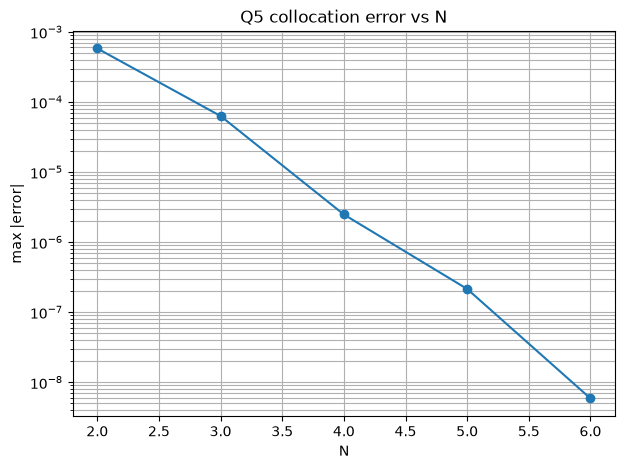

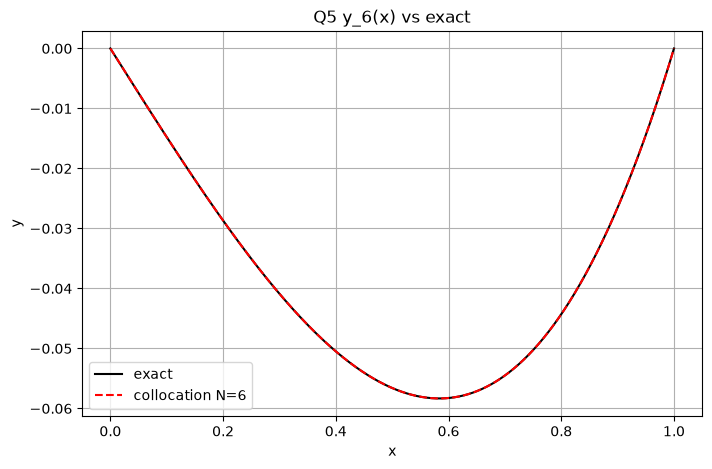


                method  unknowns     max error
       collocation N=6         6    5.8747e-09
              FD h=0.1         9    4.4146e-05
             FD h=0.05        19    1.1047e-05
            FD h=0.025        39    2.7624e-06

collocation with only 6 unknowns is far more accurate than FD with 39 unknowns


In [5]:
import numpy as np
import matplotlib.pyplot as plt


def exact(x):
    return np.sinh(x)/np.sinh(1) - x


def collocation(N):
    # y_N = sum c_i x^i (1 - x) = sum c_i (x^i - x^(i+1)),  i = 1..N  (BCs hold automatically)
    # collocate y'' - y = x at x_k = k/(N+1),  k = 1..N
    A = np.zeros((N, N))
    r = np.zeros(N)
    for k in range(N):
        xk = (k + 1)/(N + 1)
        for i in range(1, N + 1):
            phi = xk**i - xk**(i + 1)
            d2 = (i*(i - 1)*xk**(i - 2) if i >= 2 else 0) - (i + 1)*i*xk**(i - 1)
            A[k, i - 1] = d2 - phi
        r[k] = xk
    return np.linalg.solve(A, r)


def evaluate(c, x):
    y = np.zeros_like(x)
    for i in range(1, len(c) + 1):
        y += c[i - 1]*x**i*(1 - x)
    return y


xx = np.linspace(0, 1, 1001)
Ns = [2, 3, 4, 5, 6]
errs = []
print(f"{'N':>3}  {'max error':>12}")
for N in Ns:
    c = collocation(N)
    e = np.abs(evaluate(c, xx) - exact(xx)).max()
    errs.append(e)
    print(f"{N:3d}  {e:12.4e}")

plt.figure(figsize=(7, 5))
plt.semilogy(Ns, errs, "o-")
plt.xlabel("N")
plt.ylabel("max |error|")
plt.title("Q5 collocation error vs N")
plt.grid(True, which="both")
plt.show()

c6 = collocation(6)
plt.figure(figsize=(8, 5))
plt.plot(xx, exact(xx), "k-", label="exact")
plt.plot(xx, evaluate(c6, xx), "r--", label="collocation N=6")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q5 y_6(x) vs exact")
plt.legend()
plt.grid()
plt.show()

# compare with finite differences of Q2 (max error at the mesh points)
def thomas(A, B, C, F):
    # tridiagonal system: A[i] y[i-1] + C[i] y[i] + B[i] y[i+1] = F[i]   (notes: Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    y = np.zeros(n)
    y[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        y[i] = alpha[i + 1]*y[i + 1] + beta[i + 1]
    return y


def fd_error(h):
    N = int(round(1/h))
    x = np.linspace(0, 1, N + 1)
    m = N - 1
    y = np.zeros(N + 1)
    y[1:N] = thomas(np.ones(m), np.ones(m), -(2 + h**2)*np.ones(m), h**2*x[1:N])
    return np.abs(y - exact(x)).max(), m


print(f"\n{'method':>22}  {'unknowns':>8}  {'max error':>12}")
print(f"{'collocation N=6':>22}  {6:8d}  {errs[-1]:12.4e}")
for h in [0.1, 0.05, 0.025]:
    e, m = fd_error(h)
    print(f"{'FD h=' + str(h):>22}  {m:8d}  {e:12.4e}")
print("\ncollocation with only 6 unknowns is far more accurate than FD with 39 unknowns")